# 08 — Non-Ensemble Supervised Models (Part 2, Phase 4)

Train **Ridge and a single decision tree for regression**, and **logistic regression and a single decision tree for classification**. These satisfy the specification's two non-ensemble models per supervised task. Reusable object-oriented code lives in `Python/supervised_models.py`.

Reuse the frozen eligible predictors, chronological partitions, task-specific expanding-month CV, and metrics from Notebook 06. Train through December 2014; compare on January 2015–December 2016. **No held-out test data are read.** Hyperparameters for each model family are selected using training CV before external validation scoring. Models saved here remain development artifacts.

In [1]:
import sys, json, platform
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.tree import plot_tree
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from Python.modelling_setup import ModellingDataSetup, ExperimentConfig
from Python.supervised_models import SupervisedExperimentConfig, SupervisedModelFactory, SupervisedExperimentRunner

OUT = PROJECT_ROOT / 'outputs' / 'supervised'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
setup = ModellingDataSetup(PROJECT_ROOT)
protocol = ExperimentConfig()
config = SupervisedExperimentConfig()
runner = SupervisedExperimentRunner(setup, OUT, config, protocol)
metadata = {'configuration': config.to_dict(), 'protocol': protocol.to_dict(),
            'split': setup.split_config, 'predictor_plan': setup.predictor_plan,
            'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'sklearn': sklearn.__version__,
            'sampling': 'None: retain every training and evaluation row',
            'selection': 'Mean training CV RMSE minimized / macro F1 maximized per family',
            'test_policy': 'Test rows remain unread',
            'convergence': 'Candidates require converged fits in all five folds'}
(OUT / 'experiment_config.json').write_text(json.dumps(metadata, indent=2))
started = perf_counter()
results = {}
display(pd.Series(config.to_dict(), name='setting').to_frame())

,setting
seed,42
blas_threads,2
ridge_alphas,"(0.1, 10.0, 1000.0)"
logistic_cs,"(0.01, 0.1, 1.0)"
tree_depths,"(5, 10, 15)"
regression_leaf_sizes,"(100, 500)"
classification_leaf_size,500
class_weights,"(None, balanced)"
logistic_max_iter,200
logistic_tol,0.001


## 1. Models, search budget, and interpretation

| Task | Model | Justification | Training-CV search |
|---|---|---|---|
| Regression | Ridge | Regularized linear reference for correlated original/engineered features | α = 0.1, 10, 1000 |
| Regression | Decision tree | Nonlinear rules and interactions, with depth/leaf constraints | depth = 5, 10, 15; minimum leaf size = 100, 500 |
| Classification | Logistic regression | Regularized probabilistic linear reference; multinomial classification | C = 0.01, 0.1, 1; class weight = None, balanced |
| Classification | Decision tree | Nonlinear multiclass rules and interactions | depth = 5, 10, 15; minimum leaf size = 500; class weight = None, balanced |

This means **45 regression CV fits**, **60 classification CV fits**, and four full-training selected-model fits. No ensembles are used. BLAS is limited to two threads; training is sequential to control memory. The logistic model uses Newton-CG, at most 200 iterations, and tolerance 0.001. Persist timing, iterations, and optimizer warnings. Exclude candidates with nonconverged CV fits; require final fits to converge. This is a small, declared search rather than an exhaustive optimization.

Unlike Notebook 07's 10,000-row training cap, these models use all available training rows. Full external training retains **466,345 regression loans** and **451,671 classification loans**, including **611 At risk** examples. Evaluation cohorts stay identical. Algorithm and training-size effects are therefore confounded when comparing with kNN; this is a practical budget comparison, not a controlled same-size algorithm experiment.

Regression uses the five full-history expanding-month folds. Classification uses the same March–December 2014 fold-validation blocks as Notebook 06, after initial training through February 2014. These folds include all three classes but retain limited early At risk support.

All imputation, scaling, and encoding are fitted on the current training fold only. Identical preprocessing is reused across candidates within that fold to avoid redundant work; none is shared across folds. All-missing historical numeric fields are dropped by the existing fitted imputer, and warnings/effective feature counts are retained in the CV tables. No later-vintage statistics are borrowed.

Balanced class weights are computed from fitting labels, not validation labels. They can improve rare-class recall while reducing accuracy or precision. Weighted-model probabilities reflect the weighted objective and should not be treated as calibrated population risks. Coefficients and tree importances describe fitted associations, not causal effects.

In [2]:
candidate_rows = []
for task in ['regression', 'classification']:
    for family, parameters in runner.factory.candidates(task):
        candidate_rows.append({'task': task, 'model': family, 'parameters': json.dumps(parameters, sort_keys=True)})
candidate_table = pd.DataFrame(candidate_rows)
candidate_table.to_csv(OUT / 'candidate_plan.csv', index=False)
display(candidate_table)
assert len(candidate_table[candidate_table.task == 'regression']) == 9
assert len(candidate_table[candidate_table.task == 'classification']) == 12

,task,model,parameters
0,regression,ridge,"{""alpha"": 0.1}"
1,regression,ridge,"{""alpha"": 10.0}"
2,regression,ridge,"{""alpha"": 1000.0}"
3,regression,decision_tree,"{""max_depth"": 5, ""min_samples_leaf"": 100}"
4,regression,decision_tree,"{""max_depth"": 5, ""min_samples_leaf"": 500}"
5,regression,decision_tree,"{""max_depth"": 10, ""min_samples_leaf"": 100}"
6,regression,decision_tree,"{""max_depth"": 10, ""min_samples_leaf"": 500}"
7,regression,decision_tree,"{""max_depth"": 15, ""min_samples_leaf"": 100}"
8,regression,decision_tree,"{""max_depth"": 15, ""min_samples_leaf"": 500}"
9,classification,logistic,"{""C"": 0.01, ""class_weight"": null}"


## 2. Regression: tune on training CV, then score full validation

Select the lowest **unweighted mean fold RMSE** separately for Ridge and the decision tree. Resolve exact ties using the sorted parameter JSON. Save selections before validation scoring. CV standard deviation describes different vintages and training sizes; it is not an independent-replicate confidence interval.

In [3]:
results['regression'] = runner.run('regression')
display(results['regression'][1])
display(results['regression'][2].dropna(axis=1, how='all'))

regression fold 1: ridge {'alpha': 0.1}; converged=True


regression fold 1: ridge {'alpha': 10.0}; converged=True


regression fold 1: ridge {'alpha': 1000.0}; converged=True


regression fold 1: decision_tree {'max_depth': 5, 'min_samples_leaf': 100}; converged=True


regression fold 1: decision_tree {'max_depth': 5, 'min_samples_leaf': 500}; converged=True


regression fold 1: decision_tree {'max_depth': 10, 'min_samples_leaf': 100}; converged=True


... (39 outputs left out)

regression decision_tree: full validation and saved-model checks complete


regression ridge: full validation and saved-model checks complete


,model,parameters,cv_mean,cv_std,n_folds,converged,mean_fit_seconds,eligible
0,decision_tree,"{""max_depth"": 10, ""min_samples_leaf"": 100}",2.685042,0.663677,5,True,0.450621,True
1,decision_tree,"{""max_depth"": 10, ""min_samples_leaf"": 500}",2.741414,0.598311,5,True,0.396481,True
2,decision_tree,"{""max_depth"": 15, ""min_samples_leaf"": 100}",2.672414,0.661951,5,True,0.524100,True
3,decision_tree,"{""max_depth"": 15, ""min_samples_leaf"": 500}",2.741150,0.597853,5,True,0.417297,True
4,decision_tree,"{""max_depth"": 5, ""min_samples_leaf"": 100}",2.762117,0.640376,5,True,0.264502,True
5,decision_tree,"{""max_depth"": 5, ""min_samples_leaf"": 500}",2.777661,0.610223,5,True,0.261921,True
6,ridge,"{""alpha"": 0.1}",2.620950,0.584602,5,True,0.013519,True
7,ridge,"{""alpha"": 10.0}",2.612851,0.584710,5,True,0.009551,True
8,ridge,"{""alpha"": 1000.0}",2.641864,0.570190,5,True,0.009844,True


,model,parameters,n_train,n_evaluation,n_features,fit_seconds,predict_seconds,train_primary,converged,fit_warnings,n_iterations,mae,rmse,r2,task,partition,preprocessing_seconds,preprocessing_notes
0,decision_tree,"{""max_depth"": 15, ""min_samples_leaf"": 100}",466345,855502,105,6.399722,0.139148,2.66094,True,,0,2.996727,3.734422,0.353611,regression,validation,2.529529,
1,ridge,"{""alpha"": 10.0}",466345,855502,105,0.067688,0.025554,2.83813,True,,0,3.163244,80.974286,-302.907580,regression,validation,2.529529,


## 3. Classification: tune macro F1 and evaluate minority outcomes

Select the highest unweighted mean fold **macro F1** separately for logistic regression and the decision tree, with fixed label order `[0 Good, 1 At risk, 2 Default]`. Record per-fold class counts and recall. Accuracy alone is inadequate; retain all required precision/recall/F1 averages and macro/micro one-versus-rest AUC. Predictions use the fitted model's default decision rule without validation-tuned thresholds.

In [4]:
results['classification'] = runner.run('classification')
display(results['classification'][1])
display(results['classification'][2].dropna(axis=1, how='all'))
elapsed = perf_counter() - started
(OUT / 'execution_summary.json').write_text(json.dumps({'total_experiment_seconds': elapsed}, indent=2))
print(f'Total experiment runtime: {elapsed / 60:.2f} minutes')

classification fold 1: logistic {'C': 0.01, 'class_weight': None}; converged=True


classification fold 1: logistic {'C': 0.01, 'class_weight': 'balanced'}; converged=True


classification fold 1: logistic {'C': 0.1, 'class_weight': None}; converged=True


classification fold 1: logistic {'C': 0.1, 'class_weight': 'balanced'}; converged=True


classification fold 1: logistic {'C': 1.0, 'class_weight': None}; converged=True


classification fold 1: logistic {'C': 1.0, 'class_weight': 'balanced'}; converged=True


... (55 outputs left out)

classification logistic: full validation and saved-model checks complete


,model,parameters,cv_mean,cv_std,n_folds,converged,mean_fit_seconds,eligible
0,decision_tree,"{""class_weight"": ""balanced"", ""max_depth"": 10, ...",0.359586,0.003946,5,True,4.726133,True
1,decision_tree,"{""class_weight"": ""balanced"", ""max_depth"": 15, ...",0.364198,0.004539,5,True,5.168253,True
2,decision_tree,"{""class_weight"": ""balanced"", ""max_depth"": 5, ""...",0.339215,0.006941,5,True,2.791788,True
3,decision_tree,"{""class_weight"": null, ""max_depth"": 10, ""min_s...",0.305312,0.003686,5,True,4.972605,True
4,decision_tree,"{""class_weight"": null, ""max_depth"": 15, ""min_s...",0.305992,0.004973,5,True,4.740727,True
5,decision_tree,"{""class_weight"": null, ""max_depth"": 5, ""min_sa...",0.298332,0.001441,5,True,2.638033,True
6,logistic,"{""C"": 0.01, ""class_weight"": ""balanced""}",0.351489,0.005377,5,True,1.452605,True
7,logistic,"{""C"": 0.01, ""class_weight"": null}",0.311349,0.004692,5,True,1.072343,True
8,logistic,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.353161,0.006584,5,True,1.726029,True
9,logistic,"{""C"": 0.1, ""class_weight"": null}",0.311528,0.004467,5,True,0.855525,True


,model,parameters,n_train,n_evaluation,n_features,fit_seconds,predict_seconds,train_primary,converged,fit_warnings,...,recall_class_0,n_train_class_0,recall_class_1,n_train_class_1,recall_class_2,n_train_class_2,task,partition,preprocessing_seconds,preprocessing_notes
0,decision_tree,"{""class_weight"": ""balanced"", ""max_depth"": 15, ...",451671,678142,113,7.636039,0.161610,0.358504,True,,...,0.666293,374560,0.307976,611,0.405384,76500,classification,validation,2.856334,
1,logistic,"{""C"": 1.0, ""class_weight"": ""balanced""}",451671,678142,113,2.064925,0.091805,0.345838,True,,...,0.671937,374560,0.459277,611,0.305659,76500,classification,validation,2.856334,


Total experiment runtime: 3.60 minutes


## 4. Selected CV metrics, optimization checks, and comparisons

Summarize every required metric over the five folds for each selected model. The selected CV score has model-selection optimism. Compare external validation results with the exact same rows from Notebooks 06 and 07. Verify targets, chronological order, and cohort sizes before presenting comparisons. No model selection uses the final test set.

In [5]:
metric_names = ['mae', 'rmse', 'r2', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
                'precision_micro', 'recall_micro', 'f1_micro', 'auc_macro_ovr', 'auc_micro_ovr',
                'recall_class_0', 'recall_class_1', 'recall_class_2']
summary_rows, selected_folds, comparisons = [], [], {}
for task, (cv, tuning, scores) in results.items():
    selection = json.loads((OUT / f'{task}_selection.json').read_text())['models']
    for family, parameters in selection.items():
        key = json.dumps(parameters, sort_keys=True)
        chosen = cv[(cv.model == family) & (cv.parameters == key)]
        assert len(chosen) == protocol.n_splits and chosen.converged.all()
        selected_folds.append(chosen)
        for metric in metric_names:
            if metric in chosen:
                summary_rows.append(dict(task=task, model=family, metric=metric,
                                         cv_mean=chosen[metric].mean(), cv_std=chosen[metric].std(ddof=1),
                                         n_valid_folds=int(chosen[metric].notna().sum())))
    previous = pd.read_csv(PROJECT_ROOT / f'outputs/knn/{task}_comparison.csv')
    comparisons[task] = pd.concat([previous, scores], ignore_index=True).dropna(axis=1, how='all')
    assert comparisons[task].n_evaluation.nunique() == 1
    comparisons[task].to_csv(OUT / f'{task}_comparison.csv', index=False)
    prior_predictions = pd.read_parquet(PROJECT_ROOT / f'outputs/knn/{task}_validation_predictions.parquet')
    target = 'int_rate' if task == 'regression' else 'target_class'
    for family in selection:
        current = pd.read_parquet(OUT / f'{task}_{family}_validation_predictions.parquet')
        np.testing.assert_array_equal(current[target], prior_predictions[target])
        np.testing.assert_array_equal(current.issue_d, prior_predictions.issue_d)
    display(Markdown(f'### {task.title()}: validation comparison'))
    metrics = ['mae', 'rmse', 'r2'] if task == 'regression' else ['accuracy', 'f1_macro', 'recall_macro', 'auc_macro_ovr']
    display(comparisons[task][['model', 'n_train', 'n_evaluation'] + metrics])
cv_summary = pd.DataFrame(summary_rows)
cv_summary.to_csv(OUT / 'selected_cv_summary.csv', index=False)
selected_folds = pd.concat(selected_folds, ignore_index=True)
selected_folds.to_csv(OUT / 'selected_cv_folds.csv', index=False)
display(cv_summary)
display(selected_folds[['task', 'model', 'partition', 'n_train', 'n_features',
                        'train_primary', 'fit_seconds', 'n_iterations', 'converged', 'fit_warnings']])
assert all(frame.converged.all() for _, _, frame in results.values())

### Regression: validation comparison

,model,n_train,n_evaluation,mae,rmse,r2
0,knn_scratch,10000,855502,2.978551,3.768190,0.341868
1,dummy_sample_mean,10000,855502,3.822251,4.740755,-0.041699
2,dummy_sample_median,10000,855502,3.788620,4.717786,-0.031630
3,dummy_mean,466345,855502,3.837982,4.752284,-0.046772
4,dummy_median,466345,855502,3.791029,4.719547,-0.032400
5,decision_tree,466345,855502,2.996727,3.734422,0.353611
6,ridge,466345,855502,3.163244,80.974286,-302.907580


### Classification: validation comparison

,model,n_train,n_evaluation,accuracy,f1_macro,recall_macro,auc_macro_ovr
0,knn_scratch,10000,678142,0.763160,0.334668,0.349702,0.565973
1,dummy_sample_prior,10000,678142,0.773577,0.290778,0.333333,0.500000
2,dummy_most_frequent,451671,678142,0.773577,0.290778,0.333333,0.500000
3,dummy_prior,451671,678142,0.773577,0.290778,0.333333,0.500000
4,decision_tree,451671,678142,0.605854,0.389358,0.459884,0.634361
5,logistic,451671,678142,0.591153,0.377292,0.478958,0.657480


,task,model,metric,cv_mean,cv_std,n_valid_folds
0,regression,decision_tree,mae,2.102277,0.501928,5
1,regression,decision_tree,rmse,2.672414,0.661951,5
2,regression,decision_tree,r2,0.462868,0.272232,5
3,regression,ridge,mae,2.043427,0.470749,5
4,regression,ridge,rmse,2.612851,0.584710,5
5,regression,ridge,r2,0.503731,0.196809,5
6,classification,decision_tree,accuracy,0.582298,0.011434,5
7,classification,decision_tree,precision_macro,0.391846,0.002843,5
8,classification,decision_tree,recall_macro,0.515043,0.039598,5
9,classification,decision_tree,f1_macro,0.364198,0.004539,5


,task,model,partition,n_train,n_features,train_primary,fit_seconds,n_iterations,converged,fit_warnings
0,regression,decision_tree,cv_1,2412,94,0.994481,0.009883,0,True,
1,regression,decision_tree,cv_2,8277,95,1.515390,0.037443,0,True,
2,regression,decision_tree,cv_3,24940,95,1.587413,0.143685,0,True,
3,regression,decision_tree,cv_4,61058,99,1.432285,0.415113,0,True,
4,regression,decision_tree,cv_5,186847,104,2.112952,2.014378,0,True,
5,regression,ridge,cv_1,2412,94,1.112710,0.002681,0,True,
6,regression,ridge,cv_2,8277,95,1.533988,0.003094,0,True,
7,regression,ridge,cv_3,24940,95,1.729534,0.005116,0,True,
8,regression,ridge,cv_4,61058,99,1.704002,0.010267,0,True,
9,regression,ridge,cv_5,186847,104,2.421092,0.026597,0,True,


## 5. Hyperparameter sensitivity and fitting gaps

The plots show candidate CV means and fold standard deviations. A low training error with much worse fold-validation error suggests limited generalization. Different feature availability and training sizes also affect early folds. Macro F1 on training and validation uses the same three-class label set.

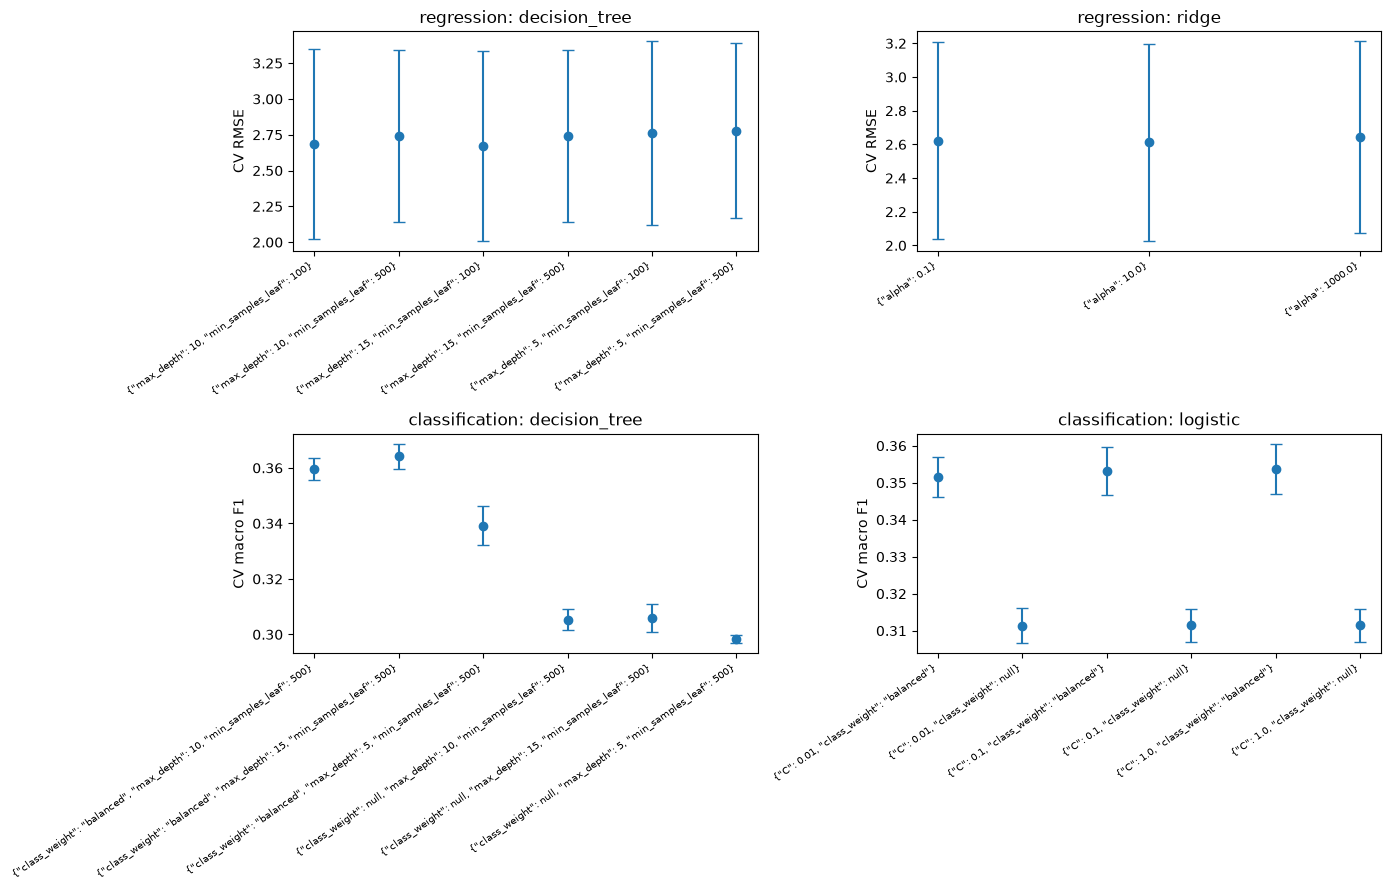

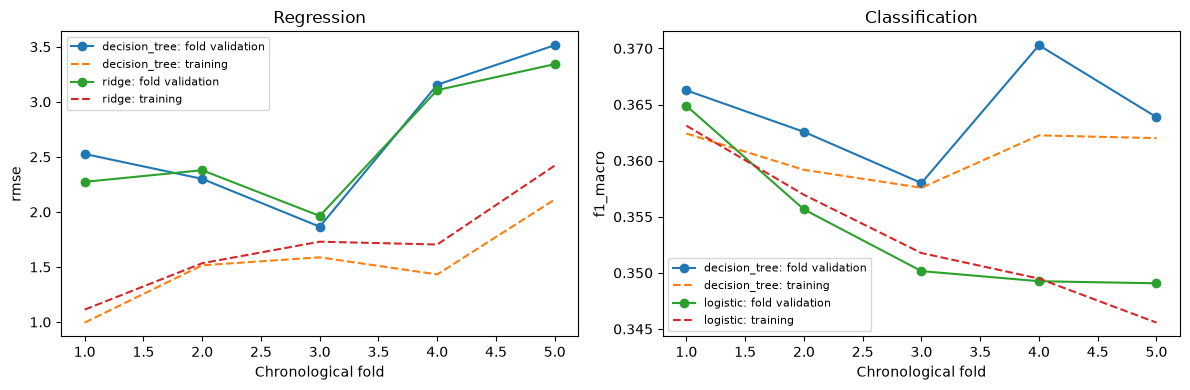

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, task in enumerate(['regression', 'classification']):
    for ax, family in zip(axes[row], sorted(results[task][1].model.unique())):
        frame = results[task][1].query('model == @family').sort_values('parameters')
        ax.errorbar(range(len(frame)), frame.cv_mean, yerr=frame.cv_std, fmt='o', capsize=4)
        ax.set_xticks(range(len(frame)), frame.parameters, rotation=35, ha='right', fontsize=7)
        ax.set(title=f'{task}: {family}', ylabel='CV RMSE' if task == 'regression' else 'CV macro F1')
fig.tight_layout()
fig.savefig(FIG / 'tuning.png', dpi=150)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, task in zip(axes, ['regression', 'classification']):
    metric = 'rmse' if task == 'regression' else 'f1_macro'
    for family, frame in selected_folds[selected_folds.task == task].groupby('model'):
        fold = frame.partition.str.extract(r'(\d+)')[0].astype(int)
        ax.plot(fold, frame[metric], marker='o', label=f'{family}: fold validation')
        ax.plot(fold, frame.train_primary, linestyle='--', label=f'{family}: training')
    ax.set(title=task.title(), xlabel='Chronological fold', ylabel=metric)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'training_cv_gaps.png', dpi=150)
plt.show()

## 6. Regression residuals and temporal errors

Use a fixed-seed display sample for scatterplots only; every error metric uses the complete validation cohort. Rate errors are in percentage points. Positive actual-minus-predicted residuals mean underprediction.

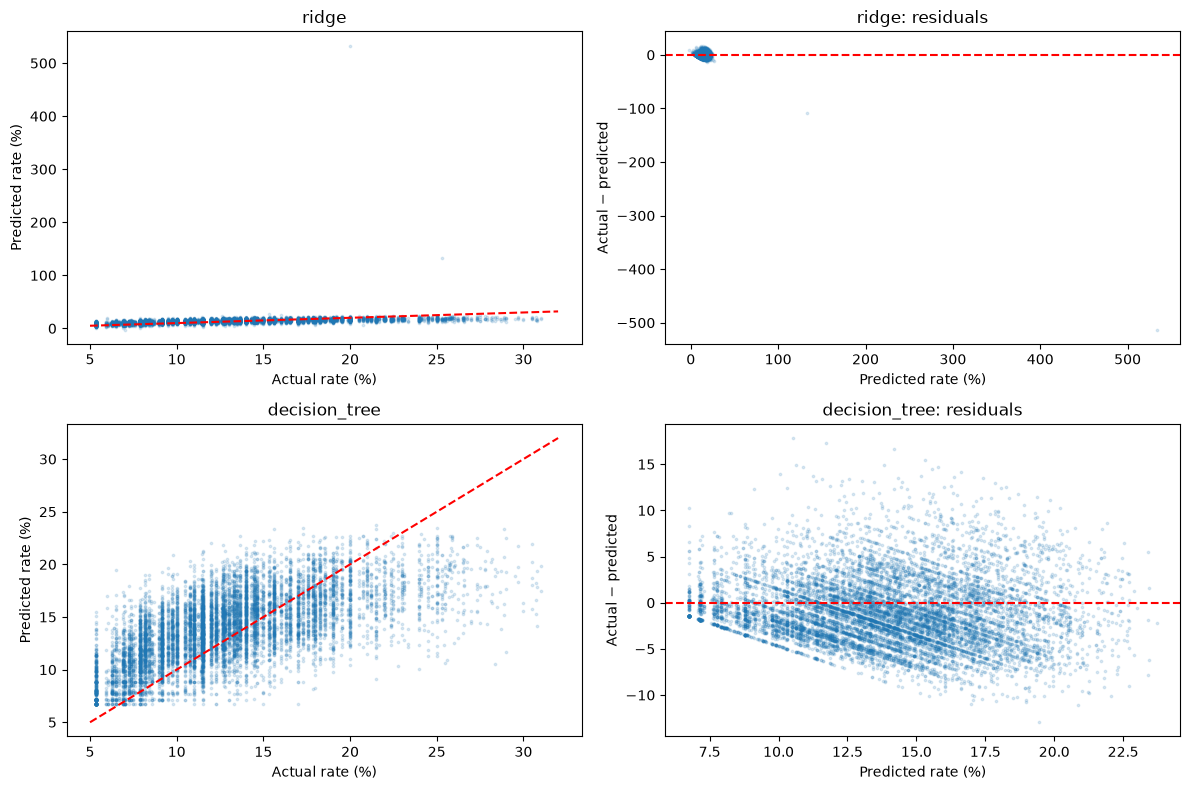

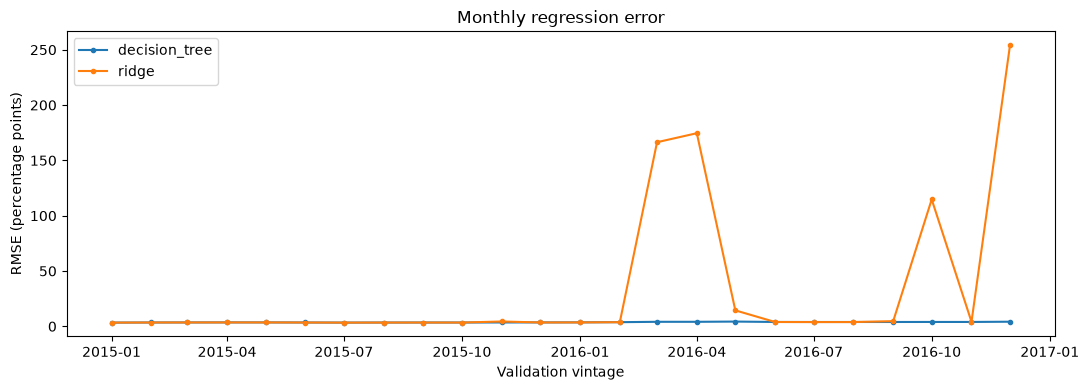

In [7]:
regression_predictions, monthly_rows = {}, []
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, family in enumerate(['ridge', 'decision_tree']):
    frame = pd.read_parquet(OUT / f'regression_{family}_validation_predictions.parquet')
    frame['residual'] = frame.int_rate - frame.prediction
    regression_predictions[family] = frame
    sample = frame.sample(n=min(10000, len(frame)), random_state=config.seed)
    axes[row, 0].scatter(sample.int_rate, sample.prediction, s=3, alpha=.15)
    axes[row, 0].plot([5, 32], [5, 32], '--', color='red')
    axes[row, 0].set(title=family, xlabel='Actual rate (%)', ylabel='Predicted rate (%)')
    axes[row, 1].scatter(sample.prediction, sample.residual, s=3, alpha=.15)
    axes[row, 1].axhline(0, color='red', linestyle='--')
    axes[row, 1].set(title=f'{family}: residuals', xlabel='Predicted rate (%)', ylabel='Actual − predicted')
    for month, group in frame.groupby(frame.issue_d.dt.to_period('M')):
        monthly_rows.append(dict(model=family, month=str(month), n=len(group),
                                 mae=group.residual.abs().mean(), rmse=np.sqrt(np.mean(group.residual ** 2)),
                                 mean_residual=group.residual.mean()))
fig.tight_layout()
fig.savefig(FIG / 'regression_diagnostics.png', dpi=150)
plt.show()
monthly = pd.DataFrame(monthly_rows)
monthly.to_csv(OUT / 'regression_monthly_errors.csv', index=False)
fig, ax = plt.subplots(figsize=(11, 4))
for family, group in monthly.groupby('model'):
    ax.plot(pd.to_datetime(group.month), group.rmse, marker='.', label=family)
ax.set(xlabel='Validation vintage', ylabel='RMSE (percentage points)', title='Monthly regression error')
ax.legend()
fig.tight_layout()
fig.savefig(FIG / 'regression_monthly_errors.png', dpi=150)
plt.show()

## 7. Classification: per-class performance, confusion matrices, and ROC

Retain class support, precision, recall, and F1. Macro AUC is the unweighted average across one-versus-rest classes. Micro AUC and accuracy are dominated by frequent classes and must not substitute for minority-class assessment. No post-hoc threshold tuning is performed here.

### logistic

,precision,recall,f1-score,support
Good,0.864323,0.671937,0.756084,524595.000000
At risk,0.032211,0.459277,0.060200,9491.000000
Default,0.326192,0.305659,0.315592,144056.000000
accuracy,0.591153,0.591153,0.591153,0.591153
macro avg,0.407575,0.478958,0.377292,678142.000000
weighted avg,0.738363,0.591153,0.652772,678142.000000


### decision_tree

,precision,recall,f1-score,support
Good,0.859332,0.666293,0.750600,524595.000000
At risk,0.032595,0.307976,0.058950,9491.000000
Default,0.321373,0.405384,0.358523,144056.000000
accuracy,0.605854,0.605854,0.605854,0.605854
macro avg,0.404433,0.459884,0.389358,678142.000000
weighted avg,0.733484,0.605854,0.657632,678142.000000


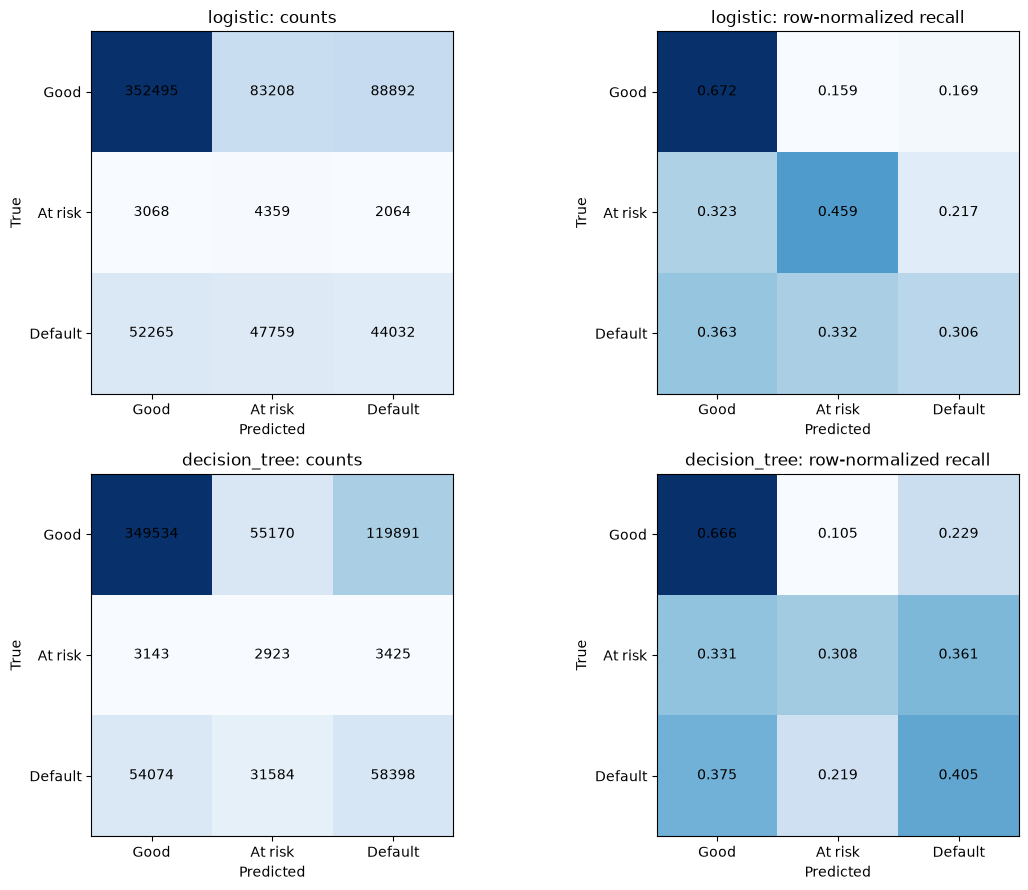

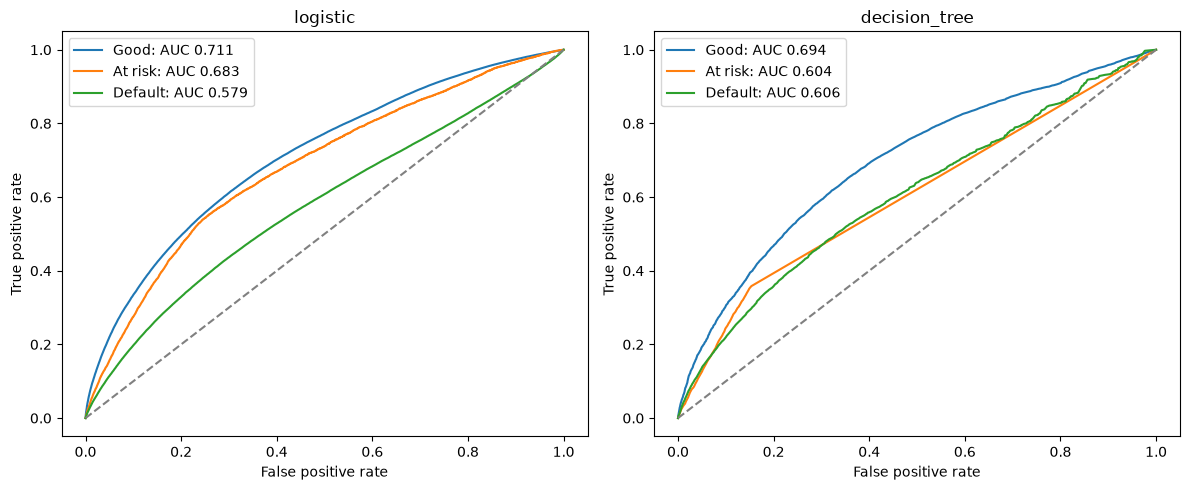

In [8]:
classification_reports, class_auc_rows = {}, []
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
roc_fig, roc_axes = plt.subplots(1, 2, figsize=(12, 5))
labels = ['Good', 'At risk', 'Default']
for row, family in enumerate(['logistic', 'decision_tree']):
    frame = pd.read_parquet(OUT / f'classification_{family}_validation_predictions.parquet')
    report = pd.DataFrame(classification_report(frame.target_class, frame.prediction, labels=[0, 1, 2],
                                               target_names=labels, zero_division=0, output_dict=True)).T
    classification_reports[family] = report
    report.to_csv(OUT / f'classification_{family}_report.csv')
    display(Markdown(f'### {family}'))
    display(report)
    matrix = confusion_matrix(frame.target_class, frame.prediction, labels=[0, 1, 2])
    pd.DataFrame(matrix, index=labels, columns=labels).to_csv(OUT / f'classification_{family}_confusion.csv')
    for ax, values, name in zip(axes[row], [matrix, matrix / matrix.sum(axis=1, keepdims=True)], ['counts', 'row-normalized recall']):
        ax.imshow(values, cmap='Blues')
        for (i, j), value in np.ndenumerate(values):
            ax.text(j, i, f'{value:.3f}' if values.dtype.kind == 'f' else str(value), ha='center', va='center')
        ax.set(xticks=range(3), yticks=range(3), xticklabels=labels, yticklabels=labels,
               xlabel='Predicted', ylabel='True', title=f'{family}: {name}')
    for label, name in enumerate(labels):
        fpr, tpr, _ = roc_curve(frame.target_class.eq(label), frame[f'probability_{label}'])
        score = auc(fpr, tpr)
        roc_axes[row].plot(fpr, tpr, label=f'{name}: AUC {score:.3f}')
        class_auc_rows.append(dict(model=family, label=name, auc=score))
    roc_axes[row].plot([0, 1], [0, 1], '--', color='gray')
    roc_axes[row].set(title=family, xlabel='False positive rate', ylabel='True positive rate')
    roc_axes[row].legend()
fig.tight_layout()
fig.savefig(FIG / 'classification_confusion_matrices.png', dpi=150)
roc_fig.tight_layout()
roc_fig.savefig(FIG / 'classification_roc.png', dpi=150)
plt.show()
pd.DataFrame(class_auc_rows).to_csv(OUT / 'classification_per_class_auc.csv', index=False)

## 8. Model interpretation and saved artifacts

Ridge coefficients use standardized numeric inputs and unscaled one-hot indicators; coefficient magnitudes across those kinds are not directly comparable. Logistic coefficients are relative softmax associations, with regularization and correlated predictors affecting allocation. Tree impurity importances can favor certain predictors and split importance across correlated features; neither proves causality. Interpret these as descriptive model diagnostics.

Save a model bundle for each selected family with the fitted preprocessor, feature order, task, split, hyperparameters, and experiment metadata. The runner checks saved/reloaded predictions (and classification probabilities) on a bounded validation slice. Models are trained on the full training cohort only. Final refitting and test evaluation remain reserved for Notebook 12.

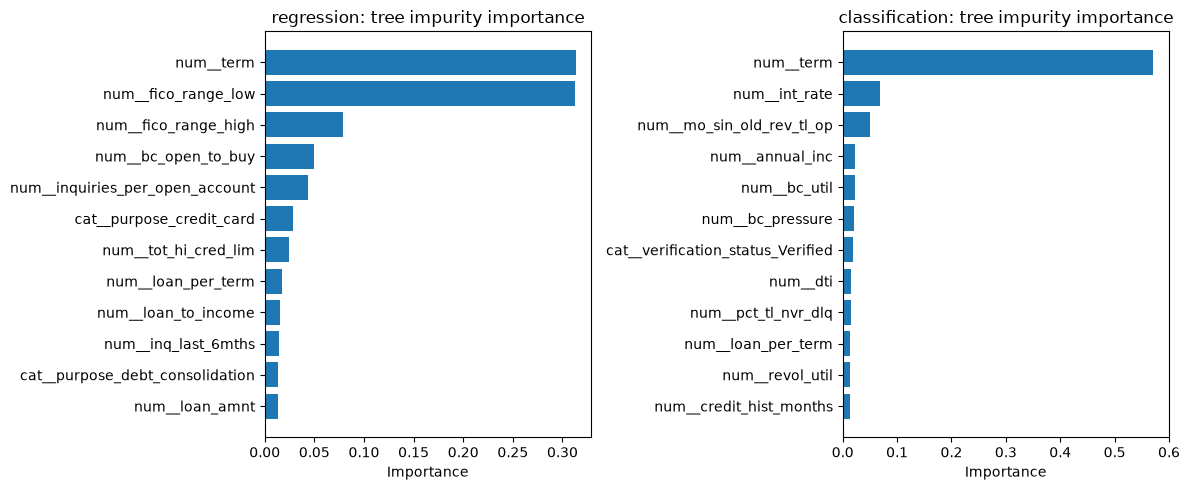

### regression: ridge coefficients

,feature,coefficient,absolute_coefficient
0,num__revol_util,7.517105,7.517105
1,num__util_x_fico,-7.202273,7.202273
2,cat__purpose_credit_card,-2.476826,2.476826
3,num__loan_amnt,2.057871,2.057871
4,cat__purpose_educational,-1.868703,1.868703
5,cat__purpose_moving,1.702668,1.702668
6,cat__purpose_small_business,1.553781,1.553781
7,num__loan_per_term,-1.548609,1.548609
8,cat__purpose_debt_consolidation,-1.283741,1.283741
9,cat__purpose_car,-1.196907,1.196907


### classification: logistic coefficients

,class,feature,coefficient,magnitude
114,1,num__term,2.224902,2.224902
1,0,num__term,-1.251719,1.251719
225,1,cat__application_type_Individual,-1.178179,1.178179
166,1,cat__purpose_house,-1.081569,1.081569
227,2,num__term,-0.973183,0.973183
161,1,cat__purpose_car,-0.766792,0.766792
168,1,cat__purpose_medical,0.754940,0.754940
151,1,num__rate_burden,-0.738919,0.738919
160,1,cat__verification_status_Verified,-0.710215,0.710215
224,1,cat__addr_state_WY,-0.701142,0.701142


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, task in zip(axes, ['regression', 'classification']):
    effects = pd.read_csv(OUT / f'{task}_decision_tree_feature_effects.csv').head(12).iloc[::-1]
    ax.barh(effects.feature, effects.importance)
    ax.set(title=f'{task}: tree impurity importance', xlabel='Importance')
fig.tight_layout()
fig.savefig(FIG / 'tree_importance.png', dpi=150)
plt.show()
for task, family in [('regression', 'ridge'), ('classification', 'logistic')]:
    display(Markdown(f'### {task}: {family} coefficients'))
    effects = pd.read_csv(OUT / f'{task}_{family}_feature_effects.csv')
    if 'class' in effects:
        display(effects.assign(magnitude=effects.coefficient.abs()).sort_values('magnitude', ascending=False).head(15))
    else:
        display(effects.head(15))

## 9. Observed results and recommendations

The generated assessment below reports validation performance without changing settings in response to it. Full-training-data versus sampled-kNN comparisons reflect both the algorithm and training budget. Fold variability is not a confidence interval on external validation performance.

Selection of funded loans, exclusion of Current loans, unequal follow-up, unidentified repeated borrowers, temporal shifts, and sparse At risk labels limit generalization. Balanced weights do not establish fairness; later group-level evaluation remains necessary. Retrospective chronological CV does not establish historical label availability or a historical backtest.

In [10]:
lines = ['# Notebook 08 — observed development results', '']
for task in ['regression', 'classification']:
    cv, tuning, scores = results[task]
    for _, row in scores.iterrows():
        family = row.model
        chosen = cv[(cv.model == family) & (cv.parameters == row.parameters)]
        if task == 'regression':
            baseline = comparisons[task].query("model == 'dummy_mean'").iloc[0]
            knn = comparisons[task].query("model == 'knn_scratch'").iloc[0]
            residual = regression_predictions[family].residual
            lines.append(f'- **Regression / {family}**, {row.parameters}: CV RMSE **{chosen.rmse.mean():.3f} ± {chosen.rmse.std(ddof=1):.3f}**; validation MAE **{row.mae:.3f}**, RMSE **{row.rmse:.3f} percentage points**, R² **{row.r2:.3f}**. RMSE reduction versus mean baseline: **{100 * (1 - row.rmse / baseline.rmse):.1f}%**. kNN RMSE: **{knn.rmse:.3f}**. Mean actual-minus-predicted residual: **{residual.mean():.3f}**.')
        else:
            report = classification_reports[family]
            lines.append(f'- **Classification / {family}**, {row.parameters}: CV macro F1 **{chosen.f1_macro.mean():.3f} ± {chosen.f1_macro.std(ddof=1):.3f}**; validation macro F1 **{row.f1_macro:.3f}**, accuracy **{row.accuracy:.2%}**, macro OVR AUC **{row.auc_macro_ovr:.3f}**. At risk precision/recall: **{report.loc["At risk", "precision"]:.2%} / {report.loc["At risk", "recall"]:.2%}**; Default precision/recall: **{report.loc["Default", "precision"]:.2%} / {report.loc["Default", "recall"]:.2%}**.')
lines += ['', '- Full external training uses 466,345 regression and 451,671 classification rows (611 At risk); kNN used 10,000. Identical validation targets/order were verified.',
          f'- Runtime: **{elapsed / 60:.2f} minutes**. All selected CV fits and external training fits converged. No test rows were read.',
          '- Improvement in macro F1 does not establish adequate minority detection. Inspect precision, recall, confusion matrices, and temporal errors before recommending a model.',
          '- Continue with bagging and boosting in Notebook 09 using these non-ensemble references. Keep final test evaluation reserved; any further changes require training/development evaluation.']
interpretation = '\n'.join(lines)
display(Markdown(interpretation))
(OUT / 'analysis.md').write_text(interpretation)

# Notebook 08 — observed development results

- **Regression / decision_tree**, {"max_depth": 15, "min_samples_leaf": 100}: CV RMSE **2.672 ± 0.662**; validation MAE **2.997**, RMSE **3.734 percentage points**, R² **0.354**. RMSE reduction versus mean baseline: **21.4%**. kNN RMSE: **3.768**. Mean actual-minus-predicted residual: **-1.037**.
- **Regression / ridge**, {"alpha": 10.0}: CV RMSE **2.613 ± 0.585**; validation MAE **3.163**, RMSE **80.974 percentage points**, R² **-302.908**. RMSE reduction versus mean baseline: **-1603.9%**. kNN RMSE: **3.768**. Mean actual-minus-predicted residual: **-1.175**.
- **Classification / decision_tree**, {"class_weight": "balanced", "max_depth": 15, "min_samples_leaf": 500}: CV macro F1 **0.364 ± 0.005**; validation macro F1 **0.389**, accuracy **60.59%**, macro OVR AUC **0.634**. At risk precision/recall: **3.26% / 30.80%**; Default precision/recall: **32.14% / 40.54%**.
- **Classification / logistic**, {"C": 1.0, "class_weight": "balanced"}: CV macro F1 **0.354 ± 0.007**; validation macro F1 **0.377**, accuracy **59.12%**, macro OVR AUC **0.657**. At risk precision/recall: **3.22% / 45.93%**; Default precision/recall: **32.62% / 30.57%**.

- Full external training uses 466,345 regression and 451,671 classification rows (611 At risk); kNN used 10,000. Identical validation targets/order were verified.
- Runtime: **3.60 minutes**. All selected CV fits and external training fits converged. No test rows were read.
- Improvement in macro F1 does not establish adequate minority detection. Inspect precision, recall, confusion matrices, and temporal errors before recommending a model.
- Continue with bagging and boosting in Notebook 09 using these non-ensemble references. Keep final test evaluation reserved; any further changes require training/development evaluation.

1831

## 10. Investigate Ridge's extreme validation errors

Ridge's modest MAE and enormous RMSE warrant an explicit audit. The following diagnostic traces the largest errors to fitted linear feature contributions and inspects application type and recorded joint income. Joint income is loaded **for auditing only**; it is not added to any model input or used to refit models. All validation observations and the original scores are retained.

This analysis is prompted by development validation results. Any future feature-policy change must be disclosed as validation-informed development and fitted within training folds, with the final test still reserved. Existing CV selection and validation scores are not overwritten by a repaired model.

In [2]:
import joblib
from Python.regression_diagnostics import RegressionDiagnostics

ridge_predictions = pd.read_parquet(OUT / 'regression_ridge_validation_predictions.parquet')
ridge_summary = RegressionDiagnostics.extreme_error_summary(ridge_predictions)
(OUT / 'ridge_extreme_error_summary.json').write_text(json.dumps(ridge_summary, indent=2))
worst = (ridge_predictions.int_rate - ridge_predictions.prediction).pow(2).nlargest(10).index
source_path = PROJECT_ROOT / 'data/processed/accepted_regression_fe.parquet'
audit_columns = ['issue_d', 'int_rate', 'annual_inc', 'annual_inc_joint', 'loan_amnt', 'loan_to_income', 'application_type']
validation_audit = pd.read_parquet(source_path, columns=audit_columns,
    filters=[('issue_d', '>=', pd.Timestamp('2015-01-01')), ('issue_d', '<', pd.Timestamp('2017-01-01'))])
validation_audit = validation_audit.sort_values('issue_d', kind='stable').reset_index(drop=True)
np.testing.assert_array_equal(validation_audit.int_rate, ridge_predictions.int_rate)
np.testing.assert_array_equal(validation_audit.issue_d, ridge_predictions.issue_d)
worst_audit = validation_audit.loc[worst].copy()
worst_audit['prediction'] = ridge_predictions.loc[worst, 'prediction']
worst_audit.index.name = 'partition_row'
worst_audit.to_csv(OUT / 'ridge_extreme_rows.csv')

training_audit = pd.read_parquet(source_path, columns=['loan_to_income', 'application_type'],
                                filters=[('issue_d', '<', pd.Timestamp('2015-01-01'))])
ratio_shift = pd.DataFrame([
    {'partition': name, 'n': len(frame), 'ratio_median': frame.loan_to_income.median(),
     'ratio_99th': frame.loan_to_income.quantile(.99), 'ratio_max': frame.loan_to_income.max(),
     'joint_applications': int(frame.application_type.eq('Joint App').sum())}
    for name, frame in [('training', training_audit), ('validation', validation_audit)]])
ratio_shift.to_csv(OUT / 'ridge_ratio_shift.csv', index=False)

bundle = joblib.load(OUT / 'regression_ridge_development_model.joblib')
validation_inputs = pd.read_parquet(source_path, columns=setup.predictors('regression') + ['issue_d'],
    filters=[('issue_d', '>=', pd.Timestamp('2015-01-01')), ('issue_d', '<', pd.Timestamp('2017-01-01'))])
validation_inputs = validation_inputs.sort_values('issue_d', kind='stable').reset_index(drop=True)
contributions = RegressionDiagnostics.linear_contributions(bundle, validation_inputs.loc[worst[:5]])
contributions.to_csv(OUT / 'ridge_extreme_prediction_contributions.csv', index=False)
display(pd.Series(ridge_summary, name='diagnostic'))
display(ratio_shift)
display(worst_audit)
display(contributions)
del validation_inputs, training_audit, validation_audit, bundle


min_prediction             -17.918098
max_prediction           48334.719939
median_absolute_error        2.576854
mse_share_top_1              0.416347
mse_share_top_10             0.997675
mse_share_top_100            0.997935
Name: diagnostic, dtype: float64

,partition,n,ratio_median,ratio_99th,ratio_max,joint_applications
0,training,466345,0.205714,0.459933,1.3375,0
1,validation,855502,0.200000,0.500000,35000.0000,9300


,issue_d,int_rate,annual_inc,annual_inc_joint,loan_amnt,loan_to_income,application_type,prediction
partition_row,,,,,,,,
848183,2016-12-01,8.24,1.0,242001.0,35000.0,35000.000000,Joint App,48334.719939
590578,2016-04-01,7.39,1.0,135347.0,24000.0,24000.000000,Joint App,33147.444489
521648,2016-03-01,8.39,1.0,190001.0,24000.0,24000.000000,Joint App,33145.427382
553781,2016-03-01,16.29,1.0,71501.0,18000.0,18000.000000,Joint App,24867.367808
755756,2016-10-01,11.39,1.0,150001.0,15000.0,15000.000000,Joint App,20722.228280
558956,2016-04-01,11.47,1.0,40001.0,2400.0,2400.000000,Joint App,3326.068792
602655,2016-05-01,9.75,1000.0,231000.0,35000.0,35.000000,Joint App,2163.544881
763334,2016-10-01,18.99,200.0,17200.0,5000.0,25.000000,Joint App,1274.520262
616015,2016-05-01,17.27,3000.0,133000.0,35000.0,11.666667,Joint App,750.122933


,partition_row,feature,contribution_percentage_points,raw_value
0,848183,num__loan_to_income,48321.362414,35000.000000
1,848183,num__loan_per_term,-5.176842,972.222222
2,848183,num__loan_amnt,5.136484,35000.000000
3,848183,cat__purpose_debt_consolidation,-1.283741,NaN
4,848183,num__total_credit_lines,-1.028156,77.000000
5,590578,num__loan_to_income,33134.553622,24000.000000
6,590578,num__revol_util,6.248884,75.900000
7,590578,num__util_x_fico,-6.115948,52371.000000
8,590578,num__loan_per_term,-2.686914,666.666667
9,590578,num__loan_amnt,2.404692,24000.000000


In [3]:
reg_scores = pd.read_csv(OUT / 'regression_validation_scores.csv').set_index('model')
clf_scores = pd.read_csv(OUT / 'classification_validation_scores.csv').set_index('model')
log_report = pd.read_csv(OUT / 'classification_logistic_report.csv', index_col=0)
tree_report = pd.read_csv(OUT / 'classification_decision_tree_report.csv', index_col=0)
ratio_info = pd.read_csv(OUT / 'ridge_ratio_shift.csv').set_index('partition')
notes = f"""
## Interpretation of the observed behaviour

**The regression tree is the strongest usable non-ensemble regression reference in this run.** Its validation RMSE is {reg_scores.loc['decision_tree', 'rmse']:.3f}, compared with kNN's 3.768 and the mean baseline's 4.752. The small advantage over kNN does not establish algorithm superiority: the tree uses the full training cohort and kNN uses only 10,000 rows. Its mean actual-minus-predicted residual is approximately −1.04 percentage points, indicating net overprediction. Predictions still compress extreme interest rates toward the middle.

**Ridge exposes a feature-support failure, despite numerical convergence.** Its validation RMSE is {reg_scores.loc['ridge', 'rmse']:.3f}; the ten largest errors account for {ridge_summary['mse_share_top_10']:.2%} of total squared error. The maximum prediction is {ridge_summary['max_prediction']:,.1f}% and is not a plausible offered rate. These rows are retained in all reported metrics. The largest-error records are joint applications with primary income as low as $1 and substantial joint income. The engineered loan-to-income feature divides by primary income only. Its maximum rises from {ratio_info.loc['training', 'ratio_max']:.4f} in training to {ratio_info.loc['validation', 'ratio_max']:,.0f} in validation, and its fitted linear contribution dominates the extreme predictions. Joint applications number {int(ratio_info.loc['training', 'joint_applications'])} in training versus {int(ratio_info.loc['validation', 'joint_applications']):,} in validation. The training data therefore do not represent this application process well. These observations do not establish that the joint-application records are erroneous. Median imputation and standardization do not protect a linear model against extrapolation of observed ratios. A successful optimizer alone does not establish a suitable model.

A defensible next development experiment would revisit joint-applicant feature eligibility and application-appropriate affordability measures, or evaluate training-fitted robust transforms and feature ablations. It must preserve prediction-time availability, avoid treating missing joint information as zero, fit all learned transforms inside folds, and explicitly acknowledge that validation revealed the problem. No such repair was silently applied here.

**Class weighting improves detection, with substantial false-positive costs.** Both classification families selected balanced weights by training CV. The tree has validation macro F1 {clf_scores.loc['decision_tree', 'f1_macro']:.3f}; logistic regression has {clf_scores.loc['logistic', 'f1_macro']:.3f}, versus kNN's 0.335 and the dummy baseline's 0.291. Tree Default recall reaches {tree_report.loc['Default', 'recall']:.1%} and At risk recall {tree_report.loc['At risk', 'recall']:.1%}; logistic At risk recall reaches {log_report.loc['At risk', 'recall']:.1%}. However, At risk precision is only {tree_report.loc['At risk', 'precision']:.1%} for the tree and {log_report.loc['At risk', 'precision']:.1%} for logistic regression: roughly 97% of At risk predictions are false positives. Accuracy falls to about 59–61%, and neither model is ready for automated lending decisions. These are useful development references, not evidence that the classification objective has been solved.

Macro AUC is higher for logistic regression ({clf_scores.loc['logistic', 'auc_macro_ovr']:.3f}) than the tree ({clf_scores.loc['decision_tree', 'auc_macro_ovr']:.3f}), while macro F1 is higher for the tree. Ranking and the chosen decision rule measure different properties. No decision threshold was tuned using external validation. The next planned notebook should compare bagging and boosting against these references, preserving all cohorts and reporting minority precision/recall. Final test data remain unread.
"""
display(Markdown(notes))
(OUT / 'analysis.md').write_text((OUT / 'analysis.md').read_text().rstrip() + '\n' + notes)



## Interpretation of the observed behaviour

**The regression tree is the strongest usable non-ensemble regression reference in this run.** Its validation RMSE is 3.734, compared with kNN's 3.768 and the mean baseline's 4.752. The small advantage over kNN does not establish algorithm superiority: the tree uses the full training cohort and kNN uses only 10,000 rows. Its mean actual-minus-predicted residual is approximately −1.04 percentage points, indicating net overprediction. Predictions still compress extreme interest rates toward the middle.

**Ridge exposes a feature-support failure, despite numerical convergence.** Its validation RMSE is 80.974; the ten largest errors account for 99.77% of total squared error. The maximum prediction is 48,334.7% and is not a plausible offered rate. These rows are retained in all reported metrics. The largest-error records are joint applications with primary income as low as $1 and substantial joint income. The engineered loan-to-income feature divides by primary income only. Its maximum rises from 1.3375 in training to 35,000 in validation, and its fitted linear contribution dominates the extreme predictions. Joint applications number 0 in training versus 9,300 in validation. The training data therefore do not represent this application process well. These observations do not establish that the joint-application records are erroneous. Median imputation and standardization do not protect a linear model against extrapolation of observed ratios. A successful optimizer alone does not establish a suitable model.

A defensible next development experiment would revisit joint-applicant feature eligibility and application-appropriate affordability measures, or evaluate training-fitted robust transforms and feature ablations. It must preserve prediction-time availability, avoid treating missing joint information as zero, fit all learned transforms inside folds, and explicitly acknowledge that validation revealed the problem. No such repair was silently applied here.

**Class weighting improves detection, with substantial false-positive costs.** Both classification families selected balanced weights by training CV. The tree has validation macro F1 0.389; logistic regression has 0.377, versus kNN's 0.335 and the dummy baseline's 0.291. Tree Default recall reaches 40.5% and At risk recall 30.8%; logistic At risk recall reaches 45.9%. However, At risk precision is only 3.3% for the tree and 3.2% for logistic regression: roughly 97% of At risk predictions are false positives. Accuracy falls to about 59–61%, and neither model is ready for automated lending decisions. These are useful development references, not evidence that the classification objective has been solved.

Macro AUC is higher for logistic regression (0.657) than the tree (0.634), while macro F1 is higher for the tree. Ranking and the chosen decision rule measure different properties. No decision threshold was tuned using external validation. The next planned notebook should compare bagging and boosting against these references, preserving all cohorts and reporting minority precision/recall. Final test data remain unread.


4999